In [1]:
# Install all external packages used in this notebook before running any other cell.
# This CUDA 12.8 PyTorch build matches the NVIDIA GPU setup checked in this project.
%pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu128
%pip install -q ultralytics albumentations opencv-python matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# YOLOv8 Bangla License Plate Detection Workflow

This notebook trains, validates, and tests YOLOv8 using the clean dataset prepared by `clean_dataset_yolov8_preprocessing.ipynb`.

Active YOLO dataset for this run:

```text
clean_dataset_processed/data.yaml
```

The older `dataset/`, `dataset_plate/`, and `dataset_processed/` preprocessing flow is kept out of the active path for this experiment.

## 1. Import Libraries and Define Paths

In [2]:
from pathlib import Path
import random
import shutil

# import albumentations as A  # old preprocessing dependency; not needed for the clean dataset run
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

# Old dataset preprocessing paths are intentionally inactive for this clean-dataset YOLOv8 run.
# ORIGINAL_DATASET = Path("dataset")
# PLATE_DATASET = Path("dataset_plate")
# PROCESSED_DATASET = Path("dataset_processed")

YOLO_DATASET = Path("clean_dataset_processed")  # active dataset used for YOLOv8 training
DATA_YAML = YOLO_DATASET / "data.yaml"
SPLITS = ["train", "valid", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(42)
np.random.seed(42)

print("YOLO training dataset:", YOLO_DATASET.resolve())
print("YOLO data.yaml:", DATA_YAML.resolve())

YOLO training dataset: D:\thesis model training\clean_dataset_processed
YOLO data.yaml: D:\thesis model training\clean_dataset_processed\data.yaml


## 2. Check GPU Availability

In [3]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    DEVICE = "cpu"
    print("GPU not detected. Training will run on CPU.")

print("Training device:", DEVICE)

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU name: NVIDIA GeForce RTX 3060
CUDA version: 12.8
Training device: 0


## 3. Verify the Active YOLO Dataset

This notebook now trains YOLOv8 from `clean_dataset_processed/`. The old `dataset/`, `dataset_plate/`, and `dataset_processed/` preprocessing flow is not used for this run.

In [4]:
assert YOLO_DATASET.exists(), f"Missing {YOLO_DATASET}. Run clean_dataset_yolov8_preprocessing.ipynb first."
assert DATA_YAML.exists(), f"Missing {DATA_YAML}. Run clean_dataset_yolov8_preprocessing.ipynb first."

for split in SPLITS:
    image_dir = YOLO_DATASET / split / "images"
    label_dir = YOLO_DATASET / split / "labels"
    assert image_dir.exists(), f"Missing image directory: {image_dir}"
    assert label_dir.exists(), f"Missing label directory: {label_dir}"

    images = sorted([path for path in image_dir.iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS])
    labels = sorted(label_dir.glob("*.txt"))
    missing_labels = [image.name for image in images if not (label_dir / f"{image.stem}.txt").exists()]

    assert not missing_labels, f"Missing labels in {split}: {missing_labels[:10]}"
    print(f"{split}: {len(images)} images and {len(labels)} label files")

print("Active YOLO data.yaml:", DATA_YAML.resolve())

train: 1543 images and 1543 label files
valid: 192 images and 192 label files
test: 194 images and 194 label files
Active YOLO data.yaml: D:\thesis model training\clean_dataset_processed\data.yaml


## 4. Skip Old Character-Level Conversion

The clean dataset is already prepared by `clean_dataset_yolov8_preprocessing.ipynb`, so this YOLO notebook does not rebuild labels from the older `dataset/` folder.

In [5]:
print("Skipping old dataset -> dataset_plate conversion.")
print("Current YOLO dataset is already prepared at:", YOLO_DATASET.resolve())

Skipping old dataset -> dataset_plate conversion.
Current YOLO dataset is already prepared at: D:\thesis model training\clean_dataset_processed


## 5. Read the Active `data.yaml`

In [6]:
assert DATA_YAML.exists(), f"Missing {DATA_YAML}. Run clean_dataset_yolov8_preprocessing.ipynb first."
print(DATA_YAML.read_text(encoding="utf-8"))

train: train/images
val: valid/images
test: test/images

nc: 1
names:
  0: license_plate



## 6. Verify Active YOLO Labels

The new dataset can contain one or more plate boxes per image. This check validates YOLO format and class id `0` for all labels.

In [7]:
def validate_yolo_label(label_path):
    errors = []
    box_count = 0

    for line_number, raw_line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
        line = raw_line.strip()
        if not line:
            continue

        parts = line.split()
        if len(parts) != 5:
            errors.append(f"line {line_number}: expected 5 values, found {len(parts)}")
            continue

        class_id_raw, x_raw, y_raw, width_raw, height_raw = parts
        try:
            class_id = int(float(class_id_raw))
            x_center = float(x_raw)
            y_center = float(y_raw)
            width = float(width_raw)
            height = float(height_raw)
        except ValueError:
            errors.append(f"line {line_number}: non-numeric value")
            continue

        if class_id != 0:
            errors.append(f"line {line_number}: class id should be 0, found {class_id}")
        if not (0.0 <= x_center <= 1.0 and 0.0 <= y_center <= 1.0):
            errors.append(f"line {line_number}: center outside [0, 1]")
        if not (0.0 < width <= 1.0 and 0.0 < height <= 1.0):
            errors.append(f"line {line_number}: invalid width/height")

        box_count += 1

    return box_count, errors


all_errors = []

for split in SPLITS:
    label_files = sorted((YOLO_DATASET / split / "labels").glob("*.txt"))
    empty_files = 0
    total_boxes = 0

    for label_path in label_files:
        box_count, errors = validate_yolo_label(label_path)
        total_boxes += box_count
        if box_count == 0:
            empty_files += 1
        for error in errors:
            all_errors.append(f"{split}/{label_path.name}: {error}")

    print(f"{split}: {len(label_files)} label files, {total_boxes} boxes, {empty_files} empty labels")

assert not all_errors, "Label validation errors:\n" + "\n".join(all_errors[:20])
print("Active YOLO labels verified successfully.")

train: 1543 label files, 1593 boxes, 0 empty labels
valid: 192 label files, 194 boxes, 0 empty labels
test: 194 label files, 199 boxes, 0 empty labels
Active YOLO labels verified successfully.


## 7. Visualize Active YOLO Labels

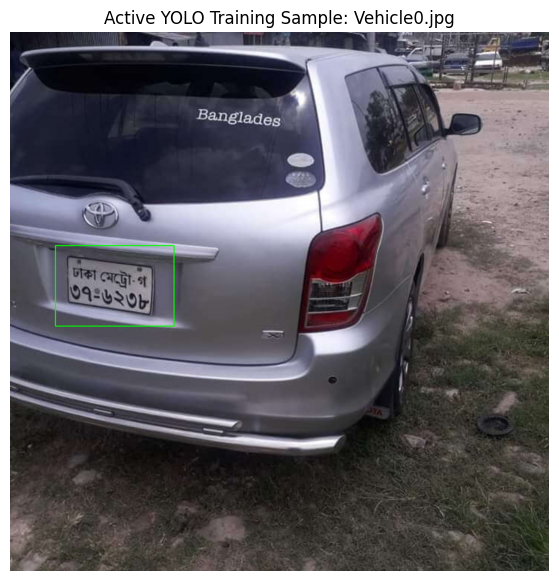

In [8]:
def find_image(image_dir, stem):
    for extension in IMAGE_EXTENSIONS:
        candidate = image_dir / f"{stem}{extension}"
        if candidate.exists():
            return candidate
    return None


def draw_yolo_boxes(image_path, label_path, color=(0, 255, 0)):
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    for line in label_path.read_text(encoding="utf-8").splitlines():
        values = line.split()
        if len(values) != 5:
            continue
        _, x_center, y_center, box_width, box_height = map(float, values)
        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)
        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)

    return image


sample_label = next(
    path for path in (YOLO_DATASET / "train" / "labels").glob("*.txt")
    if path.read_text(encoding="utf-8").strip()
)
sample_image = find_image(YOLO_DATASET / "train" / "images", sample_label.stem)
assert sample_image is not None, f"No matching image found for {sample_label.name}"

plt.figure(figsize=(10, 7))
plt.imshow(draw_yolo_boxes(sample_image, sample_label))
plt.title(f"Active YOLO Training Sample: {sample_image.name}")
plt.axis("off")
plt.show()

## 8. Legacy Augmentation Definition Skipped

In [9]:
print("No notebook-side dataset augmentation is generated for this clean-dataset run.")
print("YOLOv8 will train from:", DATA_YAML.resolve())

No notebook-side dataset augmentation is generated for this clean-dataset run.
YOLOv8 will train from: D:\thesis model training\clean_dataset_processed\data.yaml


## 9. Use Existing Clean Processed Dataset

In [10]:
assert DATA_YAML.exists(), f"Missing {DATA_YAML}. Run clean_dataset_yolov8_preprocessing.ipynb first."

for split in SPLITS:
    image_count = len([path for path in (YOLO_DATASET / split / "images").iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS])
    label_count = len(list((YOLO_DATASET / split / "labels").glob("*.txt")))
    print(f"{split}: {image_count} images, {label_count} labels")

print("Dataset ready for YOLOv8 training:", DATA_YAML.resolve())

train: 1543 images, 1543 labels
valid: 192 images, 192 labels
test: 194 images, 194 labels
Dataset ready for YOLOv8 training: D:\thesis model training\clean_dataset_processed\data.yaml


## 10. Visualize a Clean Dataset Test Sample

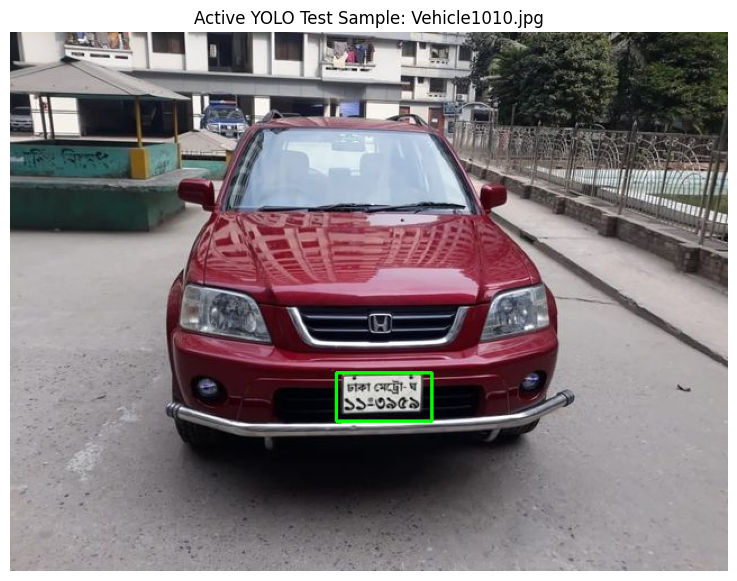

In [11]:
sample_label = next(
    path for path in (YOLO_DATASET / "test" / "labels").glob("*.txt")
    if path.read_text(encoding="utf-8").strip()
)
sample_image = find_image(YOLO_DATASET / "test" / "images", sample_label.stem)
assert sample_image is not None, f"No matching image found for {sample_label.name}"

plt.figure(figsize=(10, 7))
plt.imshow(draw_yolo_boxes(sample_image, sample_label))
plt.title(f"Active YOLO Test Sample: {sample_image.name}")
plt.axis("off")
plt.show()

## 11. Train YOLOv8

 `yolov8s.pt` generally provides better accuracy than `yolov8n.pt`. Change `BATCH_SIZE` to `4` if GPU memory is limited.

In [12]:
from pathlib import Path
from ultralytics import YOLO

MODEL_WEIGHTS = "yolov8s.pt"
EPOCHS = 30 
IMAGE_SIZE = 640
BATCH_SIZE = 16

RUN_PROJECT = (Path("runs") / "bangla_plate_yolov8").resolve()
RUN_NAME = "plate_motion_blur_distortion_exp"

YOLO_DATASET = Path("clean_dataset_processed")
DATA_YAML = YOLO_DATASET / "data.yaml"
assert DATA_YAML.exists(), f"Missing {DATA_YAML}. Run clean_dataset_yolov8_preprocessing.ipynb first."
print("Using YOLO dataset:", DATA_YAML.resolve())


model = YOLO(MODEL_WEIGHTS)

training_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=4,
    project=str(RUN_PROJECT),
    name=RUN_NAME,
    plots=True,
    save=True,
    val=True,
    exist_ok=True,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_MODEL_PATH = Path(model.trainer.best)

print("Training run directory:", RUN_DIR)
print("Best trained model:", BEST_MODEL_PATH)

Using YOLO dataset: D:\thesis model training\clean_dataset_processed\data.yaml
New https://pypi.org/project/ultralytics/8.4.59 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.54  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=clean_dataset_processed\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, m

## 12. Validate and Test the Best Model

In [13]:
best_model = YOLO(str(BEST_MODEL_PATH))

validation_metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    device=DEVICE,
)

test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    device=DEVICE,
)

prediction_results = best_model.predict(
    source=str(YOLO_DATASET / "test" / "images"),
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(RUN_DIR.parent),
    name="final_test_predictions",
    exist_ok=True,
)

prediction_dir = RUN_DIR.parent / "final_test_predictions"
print("Predictions saved at:", prediction_dir)

Ultralytics 8.4.54  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
Model summary (fused): 73 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 1240.8848.1 MB/s, size: 160.0 KB)
val: Scanning D:\thesis model training\clean_dataset_processed\valid\labels.cache... 192 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 192/192  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 2.0it/s 6.0s0.2s
                   all        192        194      0.976      0.979      0.989      0.635
Speed: 6.0ms preprocess, 13.5ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to D:\thesis model training\runs\detect\val
Ultralytics 8.4.54  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12287MiB)
val: Fast image access  (ping: 49.929.0 ms, read: 1.71.3 MB/s, size: 100.2 KB)
val: Scanning D:\thesis model training\clean_data

## 13. Plot Training Loss, Precision, and Recall

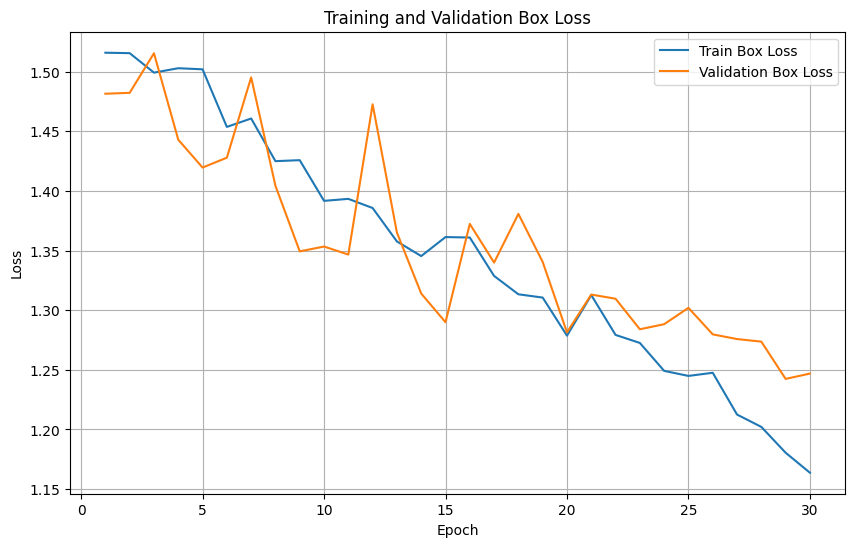

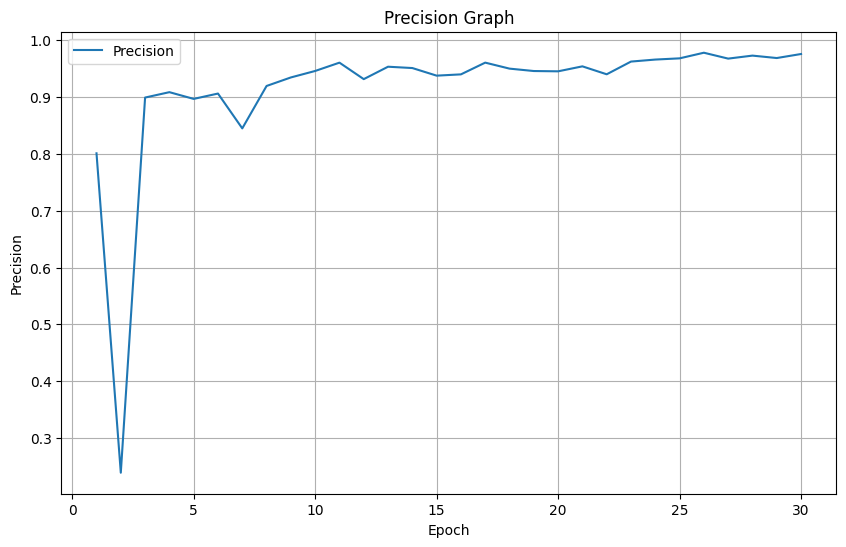

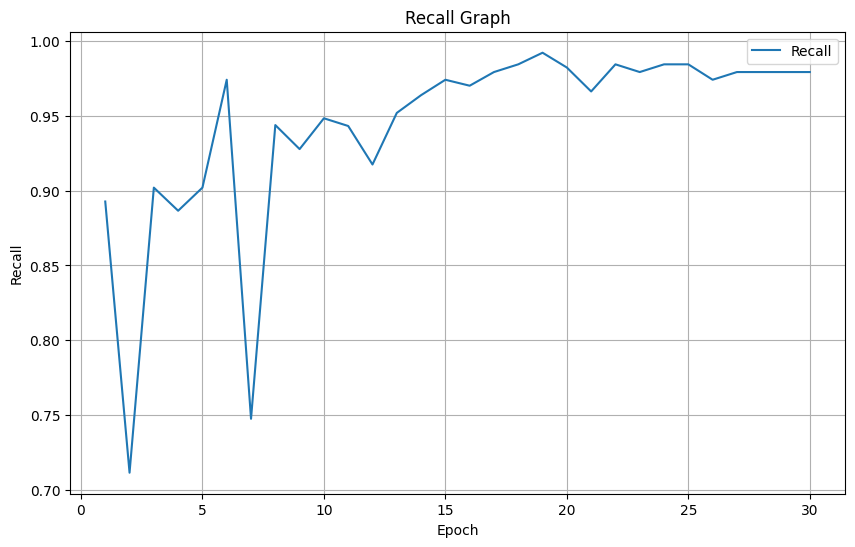

In [14]:
results_csv = RUN_DIR / "results.csv"
results_table = pd.read_csv(results_csv)
results_table.columns = results_table.columns.str.strip()

plt.figure(figsize=(10, 6))
plt.plot(results_table["epoch"], results_table["train/box_loss"], label="Train Box Loss")
plt.plot(results_table["epoch"], results_table["val/box_loss"], label="Validation Box Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Box Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(results_table["epoch"], results_table["metrics/precision(B)"], label="Precision")
plt.xlabel("Epoch")
plt.ylabel("Precision")
plt.title("Precision Graph")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(results_table["epoch"], results_table["metrics/recall(B)"], label="Recall")
plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.title("Recall Graph")
plt.legend()
plt.grid(True)
plt.show()

## 14. Show YOLOv8 Saved Thesis Outputs

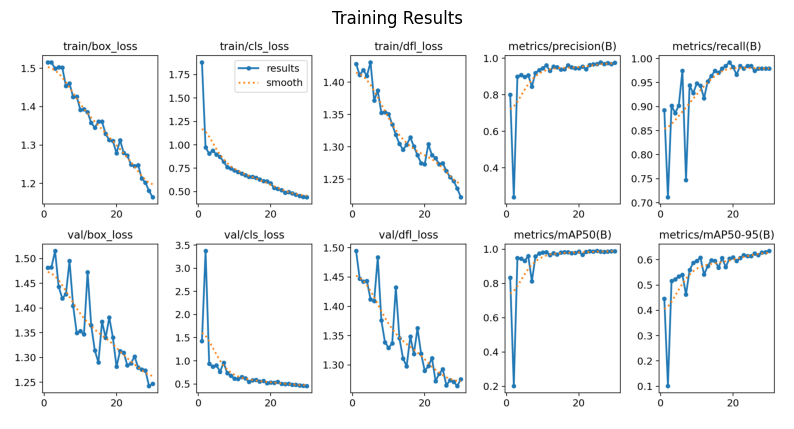

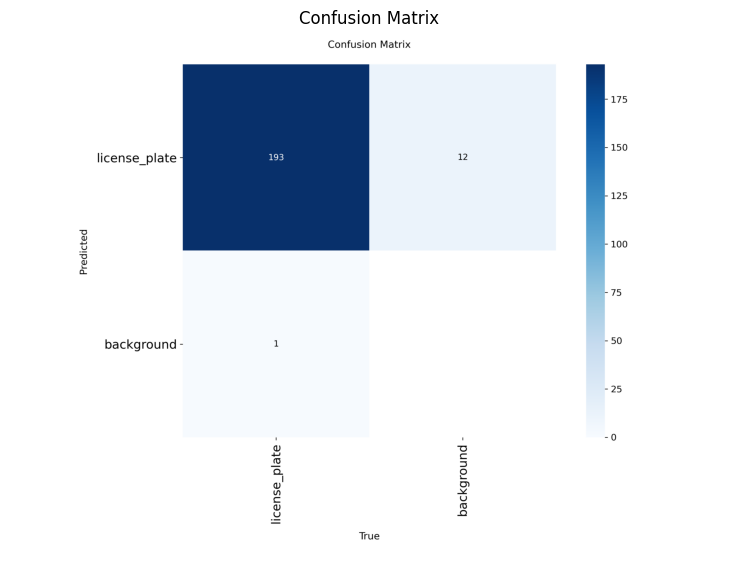

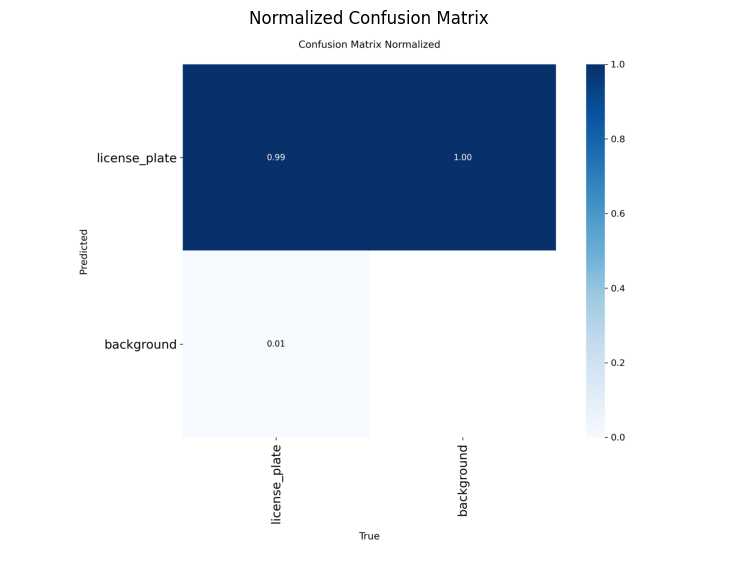

File not found: D:\thesis model training\runs\bangla_plate_yolov8\plate_motion_blur_distortion_exp\PR_curve.png
File not found: D:\thesis model training\runs\bangla_plate_yolov8\plate_motion_blur_distortion_exp\F1_curve.png


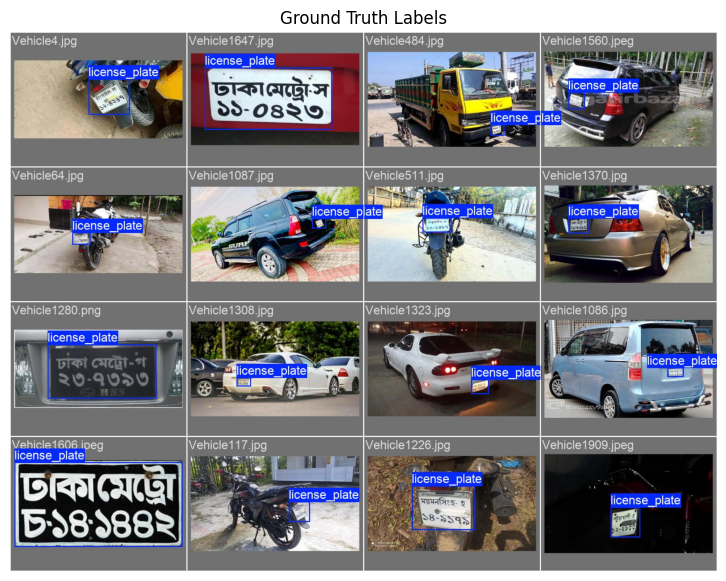

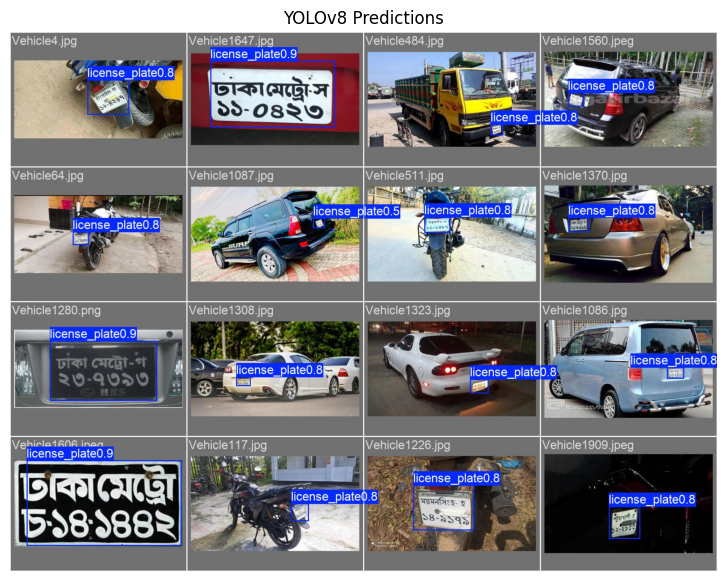

In [15]:
def show_saved_image(image_path, title):
    if not image_path.exists():
        print("File not found:", image_path)
        return
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()


show_saved_image(RUN_DIR / "results.png", "Training Results")
show_saved_image(RUN_DIR / "confusion_matrix.png", "Confusion Matrix")
show_saved_image(RUN_DIR / "confusion_matrix_normalized.png", "Normalized Confusion Matrix")
show_saved_image(RUN_DIR / "PR_curve.png", "Precision-Recall Curve")
show_saved_image(RUN_DIR / "F1_curve.png", "F1-Confidence Curve")
show_saved_image(RUN_DIR / "val_batch0_labels.jpg", "Ground Truth Labels")
show_saved_image(RUN_DIR / "val_batch0_pred.jpg", "YOLOv8 Predictions")

## 15. Generate and Show Final Test Predictions


image 1/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1010.jpg: 512x640 1 license_plate, 113.3ms
image 2/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1022.jpg: 480x640 1 license_plate, 80.3ms
image 3/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1034.jpg: 480x640 1 license_plate, 9.6ms
image 4/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1043.jpg: 640x320 1 license_plate, 10.3ms
image 5/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1083.jpg: 640x480 1 license_plate, 10.2ms
image 6/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1093.jpg: 640x512 1 license_plate, 10.4ms
image 7/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1098.jpg: 640x480 1 license_plate, 10.1ms
image 8/194 d:\thesis model training\clean_dataset_processed\test\images\Vehicle1099.jpg: 640x320 1 license_plate, 10.5ms
image 9/194 d:\thesis m

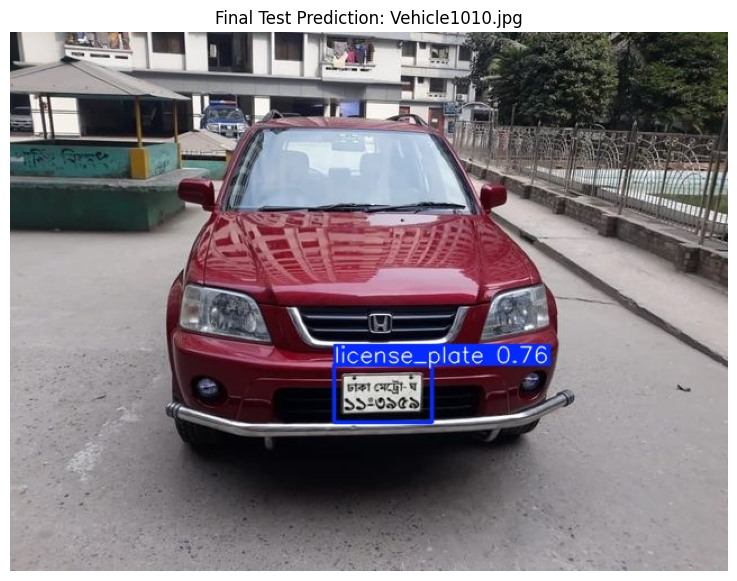

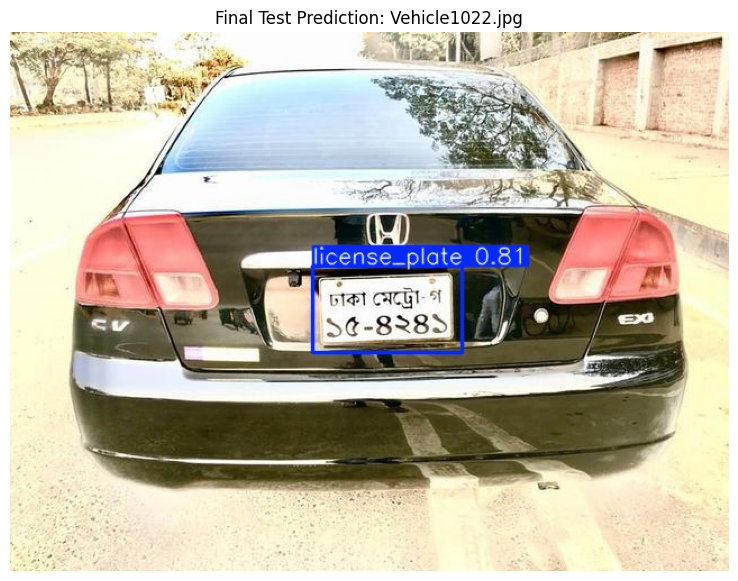

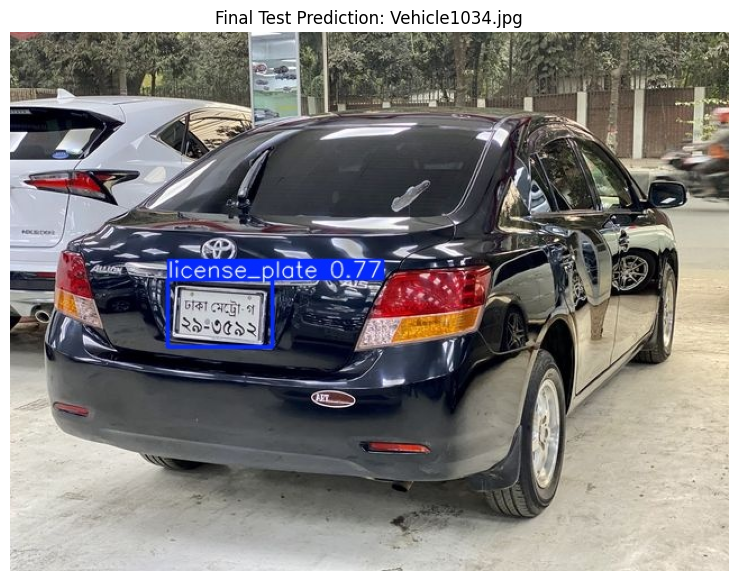

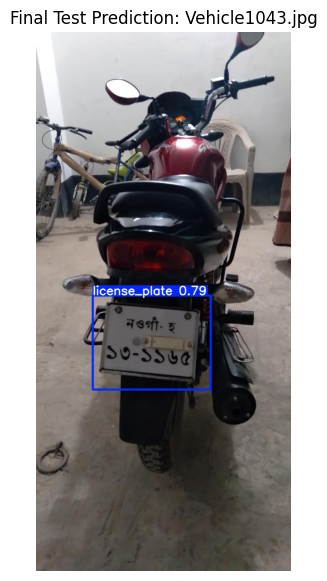

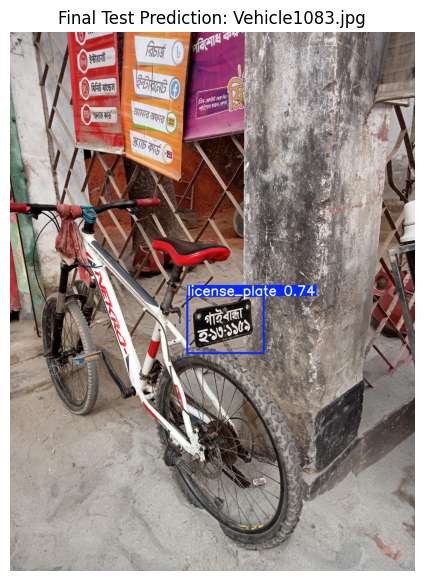

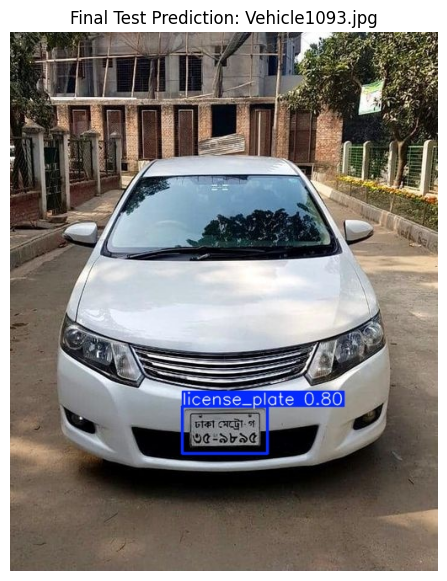

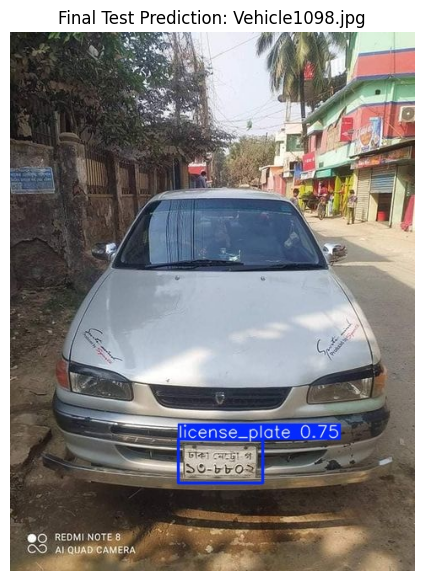

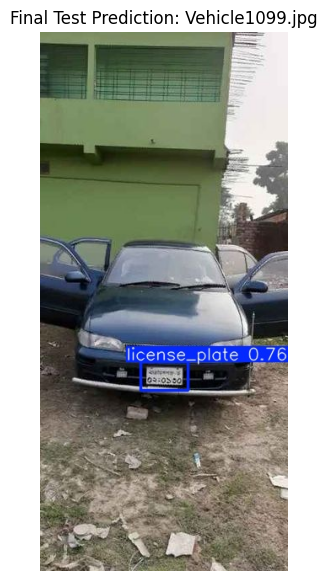

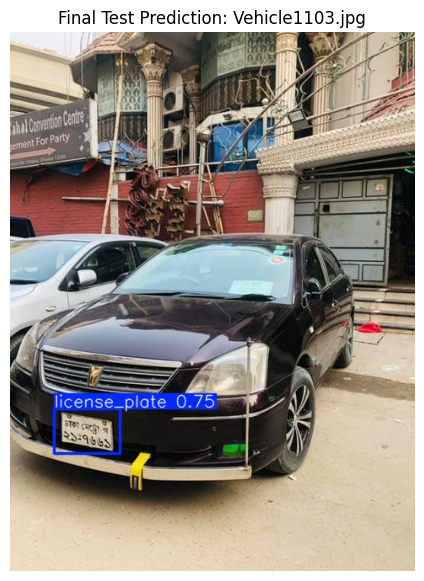

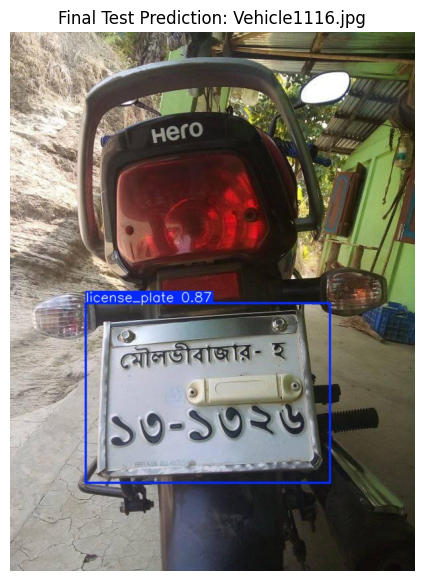

Final model saved at: D:\thesis model training\runs\bangla_plate_yolov8\plate_motion_blur_distortion_exp\weights\best.pt


In [16]:
prediction_results = best_model.predict(
    source=str(YOLO_DATASET / "test" / "images"),
    imgsz=IMAGE_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=RUN_PROJECT,
    name="final_test_predictions",
    exist_ok=True,
)

prediction_dir = Path(RUN_PROJECT) / "final_test_predictions"
prediction_images = [
    path for path in prediction_dir.iterdir()
    if path.suffix.lower() in IMAGE_EXTENSIONS
][:10]

for image_path in prediction_images:
    show_saved_image(image_path, f"Final Test Prediction: {image_path.name}")

print("Final model saved at:", BEST_MODEL_PATH)